# Video 15: Spatial Pharmacokinetics
## Measuring Drug Diffusion in Tissue from Fluorescence Microscopy Images
### AI for Drug Discovery Series | DigitalSreeni

---

### Why drug penetration matters

A drug that binds its target with high affinity and passes every ADMET test can still fail in a solid tumor if it cannot physically reach tumor cells that are far from blood vessels. Solid tumors are poorly vascularized. Cells more than a few hundred microns from the nearest vessel live in chronic low oxygen and low nutrient supply -- they are also in a zone of low drug exposure. This is one of the key reasons compounds that look excellent in cell culture disappoint in animal models and clinical trials.

**Spatial pharmacokinetics** measures how drug concentration varies in space within tissue as a function of distance from blood vessels. It answers a direct question: how far does the drug actually penetrate from a vessel into surrounding tumor tissue?

### The experiment

The standard approach uses two fluorescent labels on frozen tissue sections:

**Drug surrogate: Hoechst 33342**
Hoechst 33342 is a cell-permeable DNA-binding dye injected intravenously 1 hour before the animal is sacrificed. It exits blood vessels rapidly (half-life in blood approximately 110 seconds) and binds tightly to nuclear DNA in cells near vessels. Cells close to a vessel absorb a lot of Hoechst and appear bright. Cells far from a vessel absorb little and appear dim. The resulting fluorescence gradient directly reports drug-accessible distance from each vessel. Hoechst is excited at UV (355 nm) and emits blue at 460 nm.

**Vessel marker: CD31 antibody conjugated to AlexaFluor 555**
After the animal is sacrificed, frozen tissue sections are stained with an anti-CD31 antibody. CD31 (PECAM-1) is expressed on endothelial cells lining vessel walls. The antibody is conjugated to AlexaFluor 555, excited at 555 nm, emitting red-orange at 580 nm.

### The autofluorescence problem

Tissue autofluorescence (AF) is background light emitted by endogenous molecules: collagen, elastin, NAD(P)H, and lipofuscin. The critical point that is easy to miss:

**AF is spatially heterogeneous -- it is NOT a uniform background.**

Collagen and elastin concentrate in vessel walls and perivascular stroma. They are strongly excited at UV (355 nm -- the same wavelength as Hoechst). This means vessel walls and the tissue immediately surrounding them are the BRIGHTEST regions in autofluorescence. This partially mimics the Hoechst gradient and, if not subtracted, causes you to overestimate the drug diffusion length constant lambda.

The AF reference channel (Channel 2) is acquired from the same tissue section at a wavelength where neither Hoechst nor CD31 emit but AF is still present. It captures the spatially structured AF pattern including the elevated perivascular signal from collagen and elastin.

### What the raw image channels contain

- **Channel 0 (CD31-AF555)**: true vessel signal + ~12% structured AF (lower at 555 nm)
- **Channel 1 (Hoechst 33342)**: true drug gradient + ~25% structured AF (stronger at UV)
- **Channel 2 (AF reference)**: spatially structured AF from same section (bright at vessel walls)

The input TIFF is generated by `create_realistic_channels.py`, which constructs a biologically realistic AF map from the vessel channel (collagen and elastin co-locate with vessels) and mixes it into both acquisition channels.

### Pipeline

1. Load 3-channel TIFF, display each in biological color
2. Subtract structured AF from Hoechst channel using AF reference
3. Segment vessel network from CD31 channel
4. Compute distance map (how far is every pixel from the nearest vessel?)
5. Extract intensity-distance profile from corrected Hoechst channel
6. Fit exponential decay model, extract diffusion length constant lambda
7. Two-condition comparison
8. Summary figure and save results

---
## Cell 1: Install libraries and set up the environment

Key libraries:
- **tifffile**: reads and writes 16-bit multichannel TIFF files in the format used by microscopes and FIJI/ImageJ.
- **scikit-image**: Otsu thresholding and morphological operations for vessel segmentation.
- **scipy.ndimage**: `distance_transform_edt` for the distance map, `gaussian_filter` for the simulated second condition.
- **scipy.optimize**: `curve_fit` for exponential decay fitting.

Before running this notebook, run `create_realistic_channels.py` to generate:
`Video15_spatial_pk/data/spatial_pk_multichannel.tif`

In [ ]:
import subprocess
subprocess.run(['pip', 'install', 'scikit-image', 'tifffile', '-q'], check=True)

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
import csv

import tifffile
import skimage
from skimage.filters import threshold_otsu
from skimage import morphology, measure
from scipy.ndimage import distance_transform_edt, gaussian_filter
from scipy.optimize import curve_fit
import scipy

matplotlib.rcParams['font.family']       = 'DejaVu Sans'
matplotlib.rcParams['axes.spines.top']   = False
matplotlib.rcParams['axes.spines.right'] = False

NAVY  = '#1B2A4A'
TEAL  = '#0D9488'
AMBER = '#F59E0B'
RED   = '#DC2626'

# Colormaps matching biological fluorophore emission colors
# CD31-AlexaFluor 555: red-orange (580 nm emission)
CMAP_CD31    = LinearSegmentedColormap.from_list('cd31',    ['black', '#FF6B35'], N=256)
# Hoechst 33342: blue (460 nm emission)
CMAP_HOECHST = LinearSegmentedColormap.from_list('hoechst', ['black', '#4FC3F7'], N=256)
# AF reference: green (conventional color for autofluorescence in the literature)
CMAP_AF      = LinearSegmentedColormap.from_list('af',      ['black', '#69F0AE'], N=256)

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR    = Path('/content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/data')
    RESULTS_DIR = Path('/content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results')
else:
    DATA_DIR    = Path('/content/data')
    RESULTS_DIR = Path('/tmp/video15_results')

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print('Environment ready.')
print(f'  scikit-image : {skimage.__version__}')
print(f'  scipy        : {scipy.__version__}')
print(f'  numpy        : {np.__version__}')
print(f'  Data dir     : {DATA_DIR}')
print(f'  Results dir  : {RESULTS_DIR}')

Mounted at /content/drive
Environment ready.
  scikit-image : 0.25.2
  scipy        : 1.16.3
  numpy        : 2.0.2
  Data dir     : /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/data
  Results dir  : /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results


---
## Cell 2: Load the 3-channel TIFF

We load the 16-bit TIFF produced by `create_realistic_channels.py`. Each channel is a 2D array of intensity values from 0 to 65535 (16-bit). We normalize to float32 (0-1) for processing but print the raw 16-bit statistics so you can see the actual signal levels.

16-bit depth is essential for fluorescence microscopy. The Hoechst gradient spans a roughly 78-fold range between the brightest perivascular cells and the dimmest distant cells. An 8-bit image (256 levels) would compress that range and lose detail in the low-signal regions far from vessels.

In [ ]:
TIFF_PATH = DATA_DIR / 'spatial_pk_multichannel.tif'
print(f'Loading: {TIFF_PATH}')

stack_16 = tifffile.imread(TIFF_PATH)   # shape: (3, H, W), dtype uint16
print(f'Stack shape : {stack_16.shape}  -- (channels, height, width)')
print(f'Data type   : {stack_16.dtype}  -- 16-bit (range 0-65535)')

NAMES = [
    'Ch 0: CD31-AlexaFluor 555   (vessel + structured AF at 555 nm)',
    'Ch 1: Hoechst 33342         (drug gradient + structured AF at UV)',
    'Ch 2: AF reference          (blank channel, same section)',
]
print('\nChannel statistics (raw 16-bit counts, 0-65535):')
for i, name in enumerate(NAMES):
    ch = stack_16[i]
    print(f'  {name}')
    print(f'    min={ch.min():6d}  max={ch.max():6d}  '
          f'mean={ch.mean():7.0f}  std={ch.std():6.0f}')

stack_f = stack_16.astype(np.float32) / 65535.0
H, W    = stack_f.shape[1], stack_f.shape[2]

ch_vessel  = stack_f[0]   # CD31-AF555
ch_hoechst = stack_f[1]   # Hoechst 33342 (drug + AF)
ch_af_ref  = stack_f[2]   # AF reference

print(f'\nNormalized to float32 (0-1). Image size: {H} x {W} pixels.')
print('ch_vessel  = CD31-AF555  (vessel + structured AF)')
print('ch_hoechst = Hoechst 33342  (drug + structured AF)')
print('ch_af_ref  = AF reference  (for subtraction)')

Loading: /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/data/spatial_pk_multichannel.tif
Stack shape : (3, 1254, 1254)  -- (channels, height, width)
Data type   : uint16  -- 16-bit (range 0-65535)

Channel statistics (raw 16-bit counts, 0-65535):
  Ch 0: CD31-AlexaFluor 555   (vessel + structured AF at 555 nm)
    min=     0  max= 65535  mean=  10136  std= 14460
  Ch 1: Hoechst 33342         (drug gradient + structured AF at UV)
    min=     0  max= 65535  mean=  25107  std= 19623
  Ch 2: AF reference          (blank channel, same section)
    min=   913  max= 65535  mean=  16067  std=  8531

Normalized to float32 (0-1). Image size: 1254 x 1254 pixels.
ch_vessel  = CD31-AF555  (vessel + structured AF)
ch_hoechst = Hoechst 33342  (drug + structured AF)
ch_af_ref  = AF reference  (for subtraction)


---
## Cell 3: Display all three channels in biological colors

Fluorescence images are always grayscale intensity data. Colors are assigned during visualization to match the emission wavelength of each fluorophore or a biological convention.

- **Red-orange** for CD31-AlexaFluor 555 (emission 580 nm)
- **Blue** for Hoechst 33342 (emission 460 nm)
- **Green** for the AF reference (conventional color for autofluorescence in the literature)

Look carefully at the AF reference (green) panel: vessel wall positions appear BRIGHT, not dark. This is the key difference from a naive uniform AF model. Collagen and elastin concentrate at vessel walls, making the vessel wall regions autofluorescent. This elevated perivascular AF bleeds into the Hoechst channel and must be subtracted before the distance analysis.

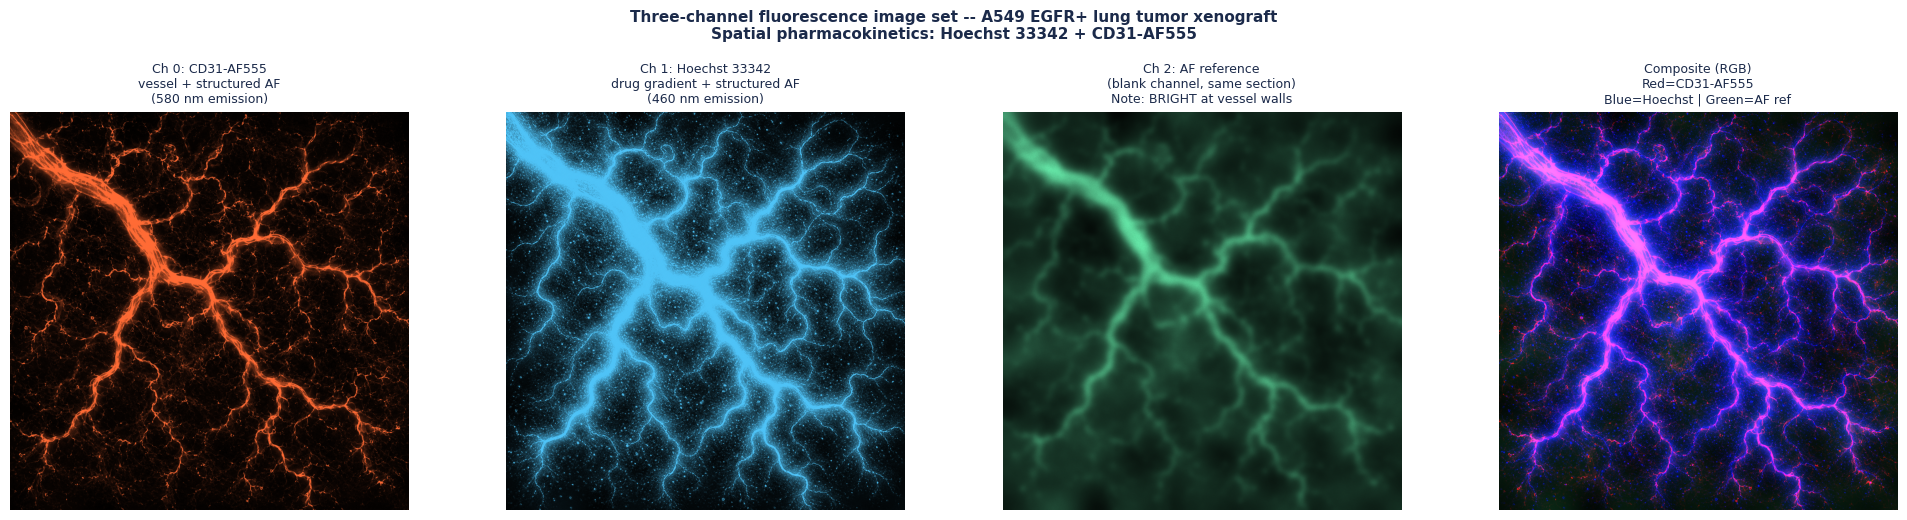

Saved to /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results/fig1_three_channels.png


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(ch_vessel, cmap=CMAP_CD31, vmin=0, vmax=1)
axes[0].set_title('Ch 0: CD31-AF555\nvessel + structured AF\n(580 nm emission)', fontsize=9, color=NAVY)
axes[0].axis('off')

axes[1].imshow(ch_hoechst, cmap=CMAP_HOECHST, vmin=0, vmax=1)
axes[1].set_title('Ch 1: Hoechst 33342\ndrug gradient + structured AF\n(460 nm emission)', fontsize=9, color=NAVY)
axes[1].axis('off')

axes[2].imshow(ch_af_ref, cmap=CMAP_AF, vmin=0, vmax=1)
axes[2].set_title('Ch 2: AF reference\n(blank channel, same section)\nNote: BRIGHT at vessel walls', fontsize=9, color=NAVY)
axes[2].axis('off')

# Composite: Red=CD31, Blue=Hoechst, Green=AF
composite = np.stack([
    ch_vessel  / max(ch_vessel.max(),  1e-6),
    ch_af_ref  / max(ch_af_ref.max(),  1e-6) * 0.5,
    ch_hoechst / max(ch_hoechst.max(), 1e-6),
], axis=2)
composite = np.clip(composite, 0, 1)

axes[3].imshow(composite)
axes[3].set_title('Composite (RGB)\nRed=CD31-AF555\nBlue=Hoechst | Green=AF ref', fontsize=9, color=NAVY)
axes[3].axis('off')

plt.suptitle(
    'Three-channel fluorescence image set -- A549 EGFR+ lung tumor xenograft\n'
    'Spatial pharmacokinetics: Hoechst 33342 + CD31-AF555',
    fontsize=11, fontweight='bold', color=NAVY, y=1.03
)
plt.tight_layout()
fig_path = RESULTS_DIR / 'fig1_three_channels.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {fig_path}')

---
## Cell 4: Structured autofluorescence subtraction

This is the most important preprocessing step and the one most tutorials get wrong by assuming AF is uniform.

**Why structured AF matters here:**
The AF reference channel shows that AF is brightest near vessel walls (collagen and elastin at UV excitation). The Hoechst signal is also brightest near vessel walls (perivascular cells took up the most dye). If we do not subtract AF, we measure a steeper-than-true gradient and get an underestimate of the true diffusion length lambda.

**Subtraction approach:**
We scale the AF reference to match the Hoechst channel's background level, then subtract. The scaling factor is estimated from the low-intensity region of the Hoechst image -- pixels with the lowest 20th percentile Hoechst signal are mostly AF (little true drug signal there), so the ratio of Hoechst to AF in those pixels gives the scale.

After subtraction, the perivascular background glow from collagen/elastin is removed, leaving the true Hoechst gradient.

Structured autofluorescence subtraction:
  Pixels used for scaling  : lowest 20th percentile of Hoechst
  Hoechst mean in those px : 0.0691
  AF ref mean in those px  : 0.1651
  AF scale factor          : 0.418
  Hoechst mean before : 0.3831
  Hoechst mean after  : 0.2866
  Signal reduction    : 25.2%  (structured AF background removed)


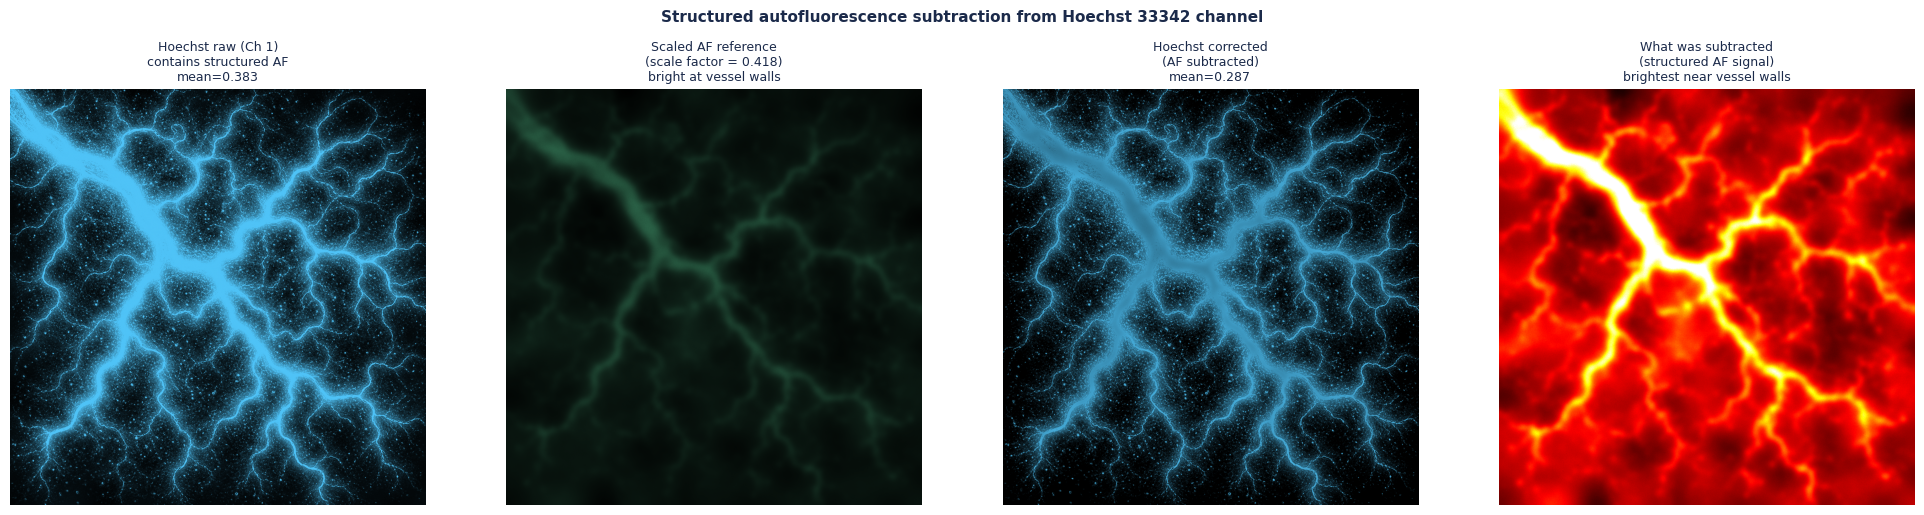

Saved to /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results/fig2_af_subtraction.png


In [ ]:
# Estimate AF scale factor from low-signal pixels
# Bottom 20th percentile of Hoechst = mostly AF, minimal true drug signal
h_flat  = ch_hoechst.flatten()
af_flat = ch_af_ref.flatten()

low_thresh = float(np.percentile(h_flat, 20))
far_mask   = h_flat < low_thresh

h_far   = float(h_flat[far_mask].mean())
af_far  = float(af_flat[far_mask].mean())
af_scale = h_far / af_far if af_far > 0 else 1.0

print('Structured autofluorescence subtraction:')
print(f'  Pixels used for scaling  : lowest 20th percentile of Hoechst')
print(f'  Hoechst mean in those px : {h_far:.4f}')
print(f'  AF ref mean in those px  : {af_far:.4f}')
print(f'  AF scale factor          : {af_scale:.3f}')

hoechst_corrected = ch_hoechst - af_scale * ch_af_ref
hoechst_corrected = np.clip(hoechst_corrected, 0.0, None)
if hoechst_corrected.max() > 0:
    hoechst_corrected = hoechst_corrected / hoechst_corrected.max()

reduction = (1.0 - hoechst_corrected.mean() / ch_hoechst.mean()) * 100
print(f'  Hoechst mean before : {ch_hoechst.mean():.4f}')
print(f'  Hoechst mean after  : {hoechst_corrected.mean():.4f}')
print(f'  Signal reduction    : {reduction:.1f}%  (structured AF background removed)')

# Visualize: show the AF that was actually removed as a difference image
af_removed = ch_hoechst - hoechst_corrected / max(hoechst_corrected.max(), 1e-6) * ch_hoechst.max()
af_removed = np.clip(af_removed, 0, None)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(ch_hoechst, cmap=CMAP_HOECHST, vmin=0, vmax=1)
axes[0].set_title(f'Hoechst raw (Ch 1)\ncontains structured AF\nmean={ch_hoechst.mean():.3f}', fontsize=9, color=NAVY)
axes[0].axis('off')

axes[1].imshow(ch_af_ref * af_scale, cmap=CMAP_AF, vmin=0, vmax=1)
axes[1].set_title(f'Scaled AF reference\n(scale factor = {af_scale:.3f})\nbright at vessel walls', fontsize=9, color=NAVY)
axes[1].axis('off')

axes[2].imshow(hoechst_corrected, cmap=CMAP_HOECHST, vmin=0, vmax=1)
axes[2].set_title(f'Hoechst corrected\n(AF subtracted)\nmean={hoechst_corrected.mean():.3f}', fontsize=9, color=NAVY)
axes[2].axis('off')

# Difference image highlights what was removed
axes[3].imshow(ch_af_ref * af_scale, cmap='hot', vmin=0, vmax=0.3)
axes[3].set_title('What was subtracted\n(structured AF signal)\nbrightest near vessel walls', fontsize=9, color=NAVY)
axes[3].axis('off')

plt.suptitle('Structured autofluorescence subtraction from Hoechst 33342 channel',
             fontsize=11, fontweight='bold', color=NAVY, y=1.02)
plt.tight_layout()
fig_path = RESULTS_DIR / 'fig2_af_subtraction.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {fig_path}')

---
## Cell 5: Vessel segmentation from the CD31 channel

We segment the vessel network from the CD31-AF555 channel using Otsu's method -- an automatic threshold that minimizes within-class variance.

The CD31 channel has high contrast between vessel walls and background even with the added AF contamination, so thresholding works reliably. The AF contamination adds a faint glow to the background (especially near vessels) but the bright endothelial rings are still far brighter than any background.

After thresholding, two morphological cleanup steps remove small debris (noise above threshold) and fill small holes inside vessel regions. The overlay panel shows the vessel mask in orange-red on top of the corrected Hoechst channel in blue -- visually confirming that the vessel mask aligns with the highest drug signal zones.

Otsu threshold: 110 (out of 255)
Vessel pixels (raw):   9.1%
Vessel pixels (clean): 8.0%
Connected vessel segments: 93


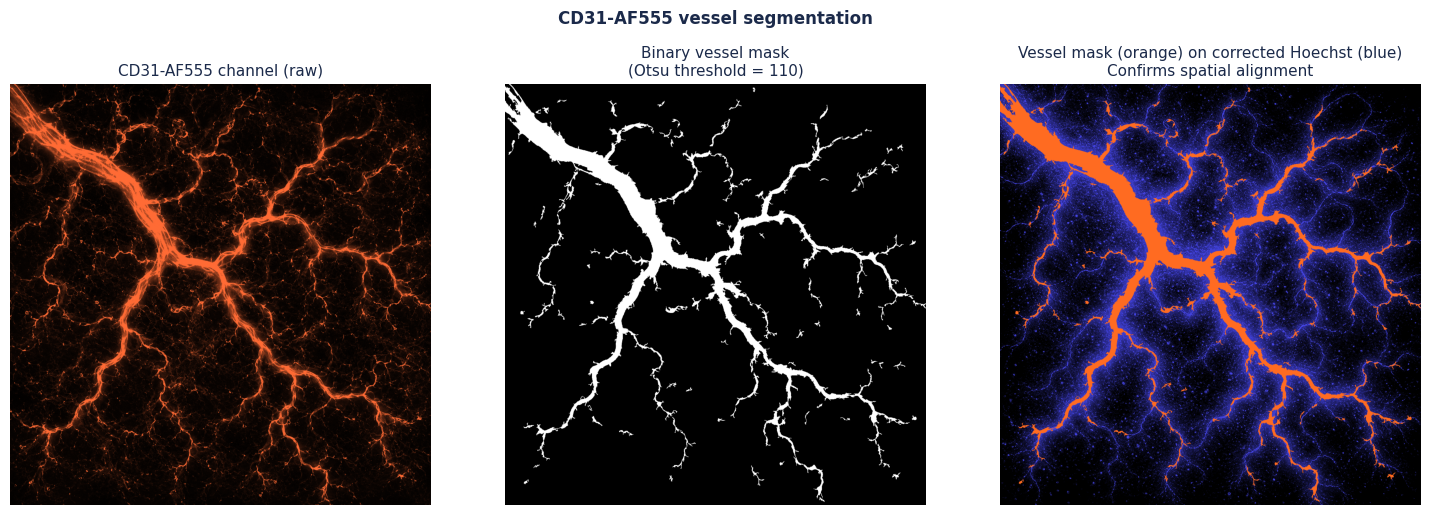

Saved to /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results/fig3_vessel_segmentation.png


In [ ]:
vessel_8bit = (ch_vessel * 255).astype(np.uint8)
otsu_thresh = threshold_otsu(vessel_8bit)
vessel_mask = vessel_8bit > otsu_thresh

print(f'Otsu threshold: {otsu_thresh} (out of 255)')
print(f'Vessel pixels (raw):   {vessel_mask.mean()*100:.1f}%')

vessel_mask = morphology.remove_small_objects(vessel_mask, min_size=60)
vessel_mask = morphology.remove_small_holes(vessel_mask, area_threshold=300)

n_segments  = int(measure.label(vessel_mask).max())
print(f'Vessel pixels (clean): {vessel_mask.mean()*100:.1f}%')
print(f'Connected vessel segments: {n_segments}')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(ch_vessel, cmap=CMAP_CD31, vmin=0, vmax=1)
axes[0].set_title('CD31-AF555 channel (raw)', fontsize=11, color=NAVY)
axes[0].axis('off')

axes[1].imshow(vessel_mask, cmap='gray')
axes[1].set_title(f'Binary vessel mask\n(Otsu threshold = {otsu_thresh})', fontsize=11, color=NAVY)
axes[1].axis('off')

# Overlay: vessel mask (orange) on corrected Hoechst (blue)
ov = np.stack([hoechst_corrected * 0.3,
               hoechst_corrected * 0.3,
               hoechst_corrected], axis=2)
ov[vessel_mask] = [1.0, 0.42, 0.13]
axes[2].imshow(np.clip(ov, 0, 1))
axes[2].set_title('Vessel mask (orange) on corrected Hoechst (blue)\nConfirms spatial alignment', fontsize=11, color=NAVY)
axes[2].axis('off')

plt.suptitle('CD31-AF555 vessel segmentation', fontsize=12, fontweight='bold', color=NAVY, y=1.02)
plt.tight_layout()
fig_path = RESULTS_DIR / 'fig3_vessel_segmentation.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {fig_path}')

---
## Cell 6: Distance transform

`distance_transform_edt` computes the Euclidean distance from every tissue pixel to the nearest vessel pixel. The output is a 2D map where each value is how far that location is from the nearest blood vessel.

This is the core of the spatial PK measurement. Once every pixel has a distance value, we can group pixels by distance and ask: what is the average Hoechst intensity at each distance? That gives the diffusion profile we fit in the next cells.

The color-coded zone overlay shows the clinical significance directly: green pixels (close to vessels) receive high drug exposure, red pixels (far from vessels) receive very little. The red zones are the clinically resistant population -- these cells survive drug treatment because the drug never reaches them at therapeutic concentrations.

Distance transform results:
  Max tissue distance from vessel : 210 pixels
  Mean tissue distance            : 38.2 pixels
  Tissue within  50 px of vessel  : 65.2%
  Tissue within 100 px of vessel  : 87.9%
  Tissue beyond 150 px of vessel  : 0.7%


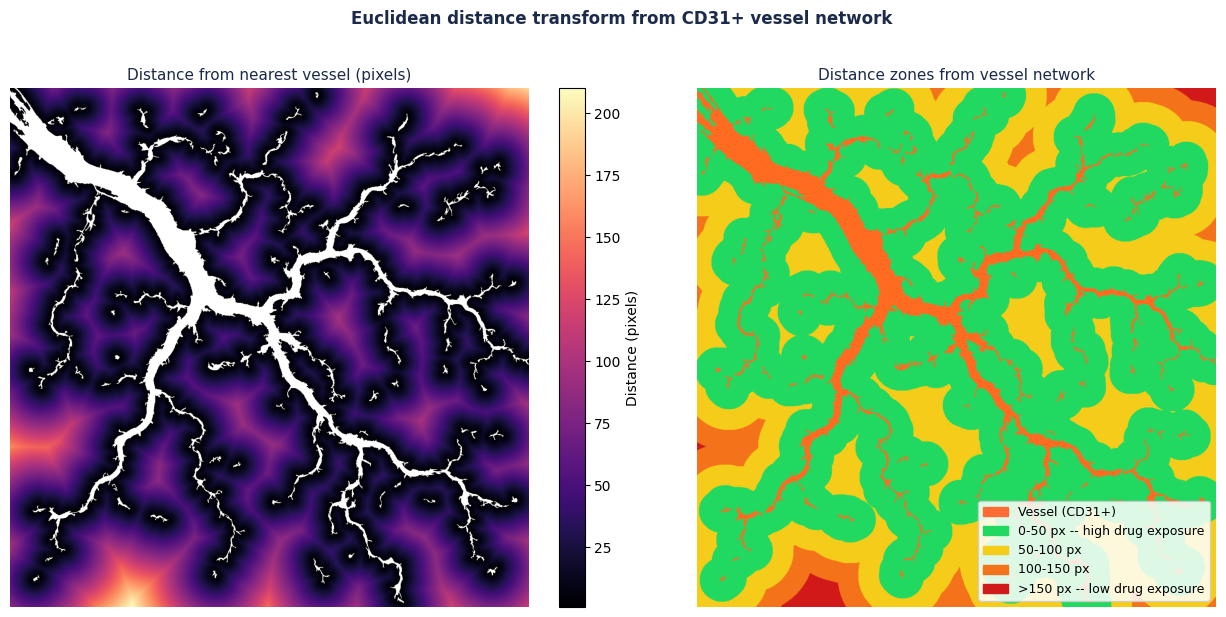

Saved to /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results/fig4_distance_transform.png


In [ ]:
dist_map = distance_transform_edt(~vessel_mask).astype(np.float32)

dist_disp = dist_map.copy()
dist_disp[vessel_mask] = np.nan

print('Distance transform results:')
print(f'  Max tissue distance from vessel : {np.nanmax(dist_disp):.0f} pixels')
print(f'  Mean tissue distance            : {np.nanmean(dist_disp):.1f} pixels')
print(f'  Tissue within  50 px of vessel  : {np.nanmean(dist_disp <  50)*100:.1f}%')
print(f'  Tissue within 100 px of vessel  : {np.nanmean(dist_disp < 100)*100:.1f}%')
print(f'  Tissue beyond 150 px of vessel  : {np.nanmean(dist_disp > 150)*100:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

im0 = axes[0].imshow(dist_disp, cmap='magma')
axes[0].set_title('Distance from nearest vessel (pixels)', fontsize=11, color=NAVY)
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046, label='Distance (pixels)')

tissue = ~vessel_mask
z0 = tissue & (dist_map <  50)
z1 = tissue & (dist_map >= 50)  & (dist_map < 100)
z2 = tissue & (dist_map >= 100) & (dist_map < 150)
z3 = tissue & (dist_map >= 150)

h  = hoechst_corrected
zrgb = np.stack([h*0.4, h*0.4, h*0.4], axis=2)
zrgb[vessel_mask] = [1.0, 0.42, 0.13]
zrgb[z0] = [0.13, 0.85, 0.38]
zrgb[z1] = [0.96, 0.80, 0.10]
zrgb[z2] = [0.96, 0.45, 0.10]
zrgb[z3] = [0.82, 0.10, 0.10]

axes[1].imshow(np.clip(zrgb, 0, 1))
axes[1].set_title('Distance zones from vessel network', fontsize=11, color=NAVY)
axes[1].axis('off')
axes[1].legend(handles=[
    mpatches.Patch(color='#FF6B35', label='Vessel (CD31+)'),
    mpatches.Patch(color='#21D961', label='0-50 px -- high drug exposure'),
    mpatches.Patch(color='#F5CC1A', label='50-100 px'),
    mpatches.Patch(color='#F5731A', label='100-150 px'),
    mpatches.Patch(color='#D11A1A', label='>150 px -- low drug exposure'),
], loc='lower right', fontsize=9, framealpha=0.85)

plt.suptitle('Euclidean distance transform from CD31+ vessel network',
             fontsize=12, fontweight='bold', color=NAVY, y=1.02)
plt.tight_layout()
fig_path = RESULTS_DIR / 'fig4_distance_transform.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {fig_path}')

---
## Cell 7: Intensity-distance profile

We group tissue pixels into distance bins (every 5 pixels) and compute the mean corrected Hoechst intensity in each bin. This converts the 2D spatial image into a 1D curve: intensity as a function of distance from the nearest vessel.

Expected shape: high intensity near vessels (perivascular cells absorbed lots of Hoechst during the 1-hour circulation period) decaying toward background at large distances.

The standard deviation within each bin reflects genuine biological heterogeneity -- cells at the same distance from a vessel vary in uptake due to local differences in perfusion, cell density, and metabolic activity. This is real biology, not measurement error.

Valid bins: 42  |  Distance range: 0 to 208 px

Profile (selected bins):
   Distance (px) |     Mean |      Std |   N pixels
  ------------------------------------------------
             2.5 |   139.16 |    56.62 |    122,603
            27.5 |    61.83 |    50.20 |    101,557
            52.5 |    33.30 |    42.58 |     63,551
            77.5 |    21.76 |    37.16 |     32,020
           102.5 |    11.98 |    28.50 |     10,481
           127.5 |     7.36 |    23.61 |      4,440
           152.5 |     4.59 |    16.53 |      1,888
           177.5 |     3.46 |    13.63 |        926
           202.5 |     1.92 |     3.71 |        185


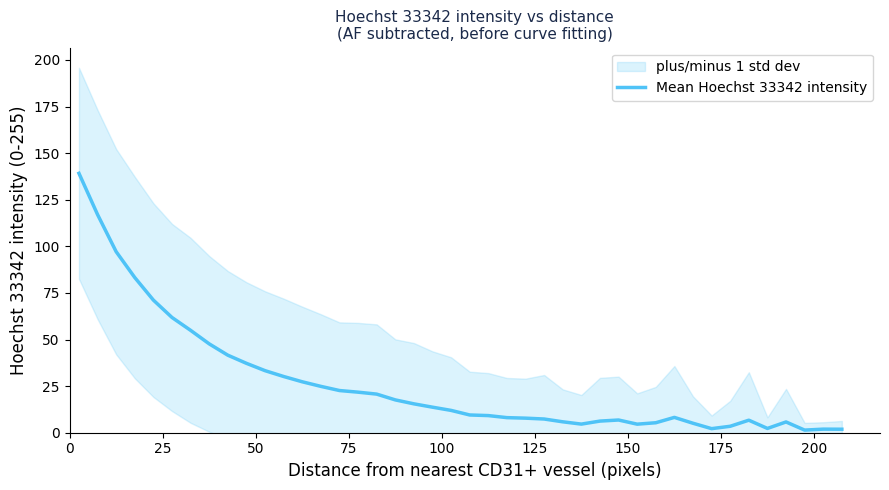

Saved to /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results/fig5_intensity_profile.png


In [ ]:
BIN_SIZE    = 5
tissue_mask = ~vessel_mask
max_d_int   = int(np.nanmax(dist_disp))
bins        = np.arange(0, max_d_int + BIN_SIZE, BIN_SIZE)
bin_centers = bins[:-1] + BIN_SIZE / 2

hoechst_8bit  = (hoechst_corrected * 255).astype(np.float32)
mean_int, std_int, n_per_bin = [], [], []

for i in range(len(bins) - 1):
    in_bin = tissue_mask & (dist_map >= bins[i]) & (dist_map < bins[i+1])
    n = int(in_bin.sum())
    if n >= 20:
        v = hoechst_8bit[in_bin]
        mean_int.append(float(v.mean()))
        std_int.append(float(v.std()))
    else:
        mean_int.append(np.nan)
        std_int.append(np.nan)
    n_per_bin.append(n)

mean_int    = np.array(mean_int)
std_int     = np.array(std_int)
bin_centers = bin_centers[:len(mean_int)]
valid       = ~np.isnan(mean_int)
x_v, y_v, s_v = bin_centers[valid], mean_int[valid], std_int[valid]

print(f'Valid bins: {valid.sum()}  |  Distance range: 0 to {x_v.max():.0f} px')
print(f'\nProfile (selected bins):')
print(f'  {"Distance (px)":>14} | {"Mean":>8} | {"Std":>8} | {"N pixels":>10}')
print(f'  {"-"*48}')
idxs = np.where(valid)[0]
for idx in idxs[::max(1, len(idxs)//8)]:
    print(f'  {bin_centers[idx]:>14.1f} | {mean_int[idx]:>8.2f} | '
          f'{std_int[idx]:>8.2f} | {n_per_bin[idx]:>10,}')

fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(x_v, y_v - s_v, y_v + s_v, color='#4FC3F7', alpha=0.2,
                label='plus/minus 1 std dev')
ax.plot(x_v, y_v, color='#4FC3F7', linewidth=2.5,
        label='Mean Hoechst 33342 intensity')
ax.set_xlabel('Distance from nearest CD31+ vessel (pixels)', fontsize=12)
ax.set_ylabel('Hoechst 33342 intensity (0-255)', fontsize=12)
ax.set_title('Hoechst 33342 intensity vs distance\n(AF subtracted, before curve fitting)',
             fontsize=11, color=NAVY)
ax.legend(fontsize=10)
ax.set_xlim(0)
ax.set_ylim(0)
plt.tight_layout()
fig_path = RESULTS_DIR / 'fig5_intensity_profile.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {fig_path}')

---
## Cell 8: Exponential decay fit -- extracting lambda

The intensity-distance profile follows an exponential decay, predicted by Fick's law of diffusion from a cylindrical source:

    I(d) = I0 * exp(-d / lambda) + C_bg

- **I0**: intensity at the vessel wall -- reflects Hoechst concentration in blood times vessel permeability
- **lambda**: the diffusion length constant -- the key output. At distance = lambda, concentration has dropped to 1/e (about 37%) of its peak. A larger lambda means better tissue penetration.
- **C_bg**: residual background after AF subtraction

Lambda in pixels multiplied by the pixel size (microns/pixel) gives a physically meaningful diffusion length. At 4x magnification on a standard CCD, pixel size is roughly 3.7 microns.

Exponential decay fit -- Hoechst 33342:
  I0     : 139.39  +/- 1.90  (peak at vessel wall)
  lambda : 33.02  +/- 0.85 pixels
  lambda : 122.2 microns  (at 3.7 um/pixel)
  C_bg   : 4.45  +/- 0.60  (residual background)
  R^2    : 0.9948

Interpretation:
  At 122 um from a CD31+ vessel: Hoechst drops to ~37% of peak.
  At 244 um from a CD31+ vessel: Hoechst drops to ~14% of peak.


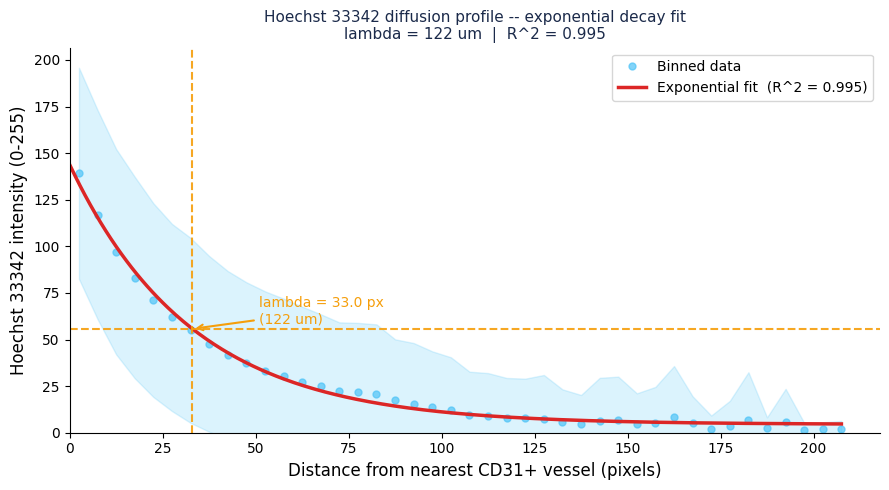

Saved to /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results/fig6_exponential_fit.png


In [ ]:
PIXEL_SIZE_UM = 3.7  # microns per pixel -- adjust for your objective

def exp_decay(d, I0, lam, bg):
    """I(d) = I0 * exp(-d/lam) + bg"""
    return I0 * np.exp(-d / lam) + bg

p0     = [float(y_v[0]), 50.0, float(y_v[-5:].mean())]
bounds = ([0, 1, 0], [255, 500, 255])
popt, pcov = curve_fit(exp_decay, x_v, y_v, p0=p0, maxfev=10000, bounds=bounds)
perr = np.sqrt(np.diag(pcov))

I0_fit, lam_fit, bg_fit = popt
I0_err, lam_err, bg_err = perr
lam_um    = lam_fit * PIXEL_SIZE_UM
y_pred    = exp_decay(x_v, *popt)
r_squared = float(1.0 - np.sum((y_v - y_pred)**2) / np.sum((y_v - y_v.mean())**2))

print('Exponential decay fit -- Hoechst 33342:')
print(f'  I0     : {I0_fit:.2f}  +/- {I0_err:.2f}  (peak at vessel wall)')
print(f'  lambda : {lam_fit:.2f}  +/- {lam_err:.2f} pixels')
print(f'  lambda : {lam_um:.1f} microns  (at {PIXEL_SIZE_UM} um/pixel)')
print(f'  C_bg   : {bg_fit:.2f}  +/- {bg_err:.2f}  (residual background)')
print(f'  R^2    : {r_squared:.4f}')
print(f'\nInterpretation:')
print(f'  At {lam_um:.0f} um from a CD31+ vessel: Hoechst drops to ~37% of peak.')
print(f'  At {2*lam_um:.0f} um from a CD31+ vessel: Hoechst drops to ~14% of peak.')

x_s = np.linspace(0, x_v.max(), 300)
y_s = exp_decay(x_s, *popt)
y_at_lam = I0_fit / np.e + bg_fit

fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(x_v, y_v - s_v, y_v + s_v, color='#4FC3F7', alpha=0.2)
ax.plot(x_v, y_v, 'o', color='#4FC3F7', markersize=5, alpha=0.7, label='Binned data')
ax.plot(x_s, y_s, '-', color=RED, linewidth=2.5,
        label=f'Exponential fit  (R^2 = {r_squared:.3f})')
ax.axvline(lam_fit, color=AMBER, linewidth=1.5, linestyle='--', alpha=0.9)
ax.axhline(y_at_lam, color=AMBER, linewidth=1.5, linestyle='--', alpha=0.9)
ax.annotate(f'lambda = {lam_fit:.1f} px\n({lam_um:.0f} um)',
            xy=(lam_fit, y_at_lam),
            xytext=(lam_fit + 18, y_at_lam + 3),
            fontsize=10, color=AMBER,
            arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.5))
ax.set_xlabel('Distance from nearest CD31+ vessel (pixels)', fontsize=12)
ax.set_ylabel('Hoechst 33342 intensity (0-255)', fontsize=12)
ax.set_title(f'Hoechst 33342 diffusion profile -- exponential decay fit\n'
             f'lambda = {lam_um:.0f} um  |  R^2 = {r_squared:.3f}',
             fontsize=11, color=NAVY)
ax.legend(fontsize=10)
ax.set_xlim(0)
ax.set_ylim(0)
plt.tight_layout()
fig_path = RESULTS_DIR / 'fig6_exponential_fit.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {fig_path}')

---
## Cell 9: Two-condition comparison

The most clinically useful application is comparing two conditions. A drug with a larger lambda reaches more tumor cells, including the poorly perfused hypoxic regions that are often the most therapy-resistant.

We simulate a second condition by applying a Gaussian blur to the corrected Hoechst channel. Blurring spreads signal outward from vessels, mimicking a smaller or more diffusible molecule. In a real experiment, these two conditions would be two different compounds imaged in separate tissue sections from matched animals.

The bar chart comparing the two lambda values (in microns) is the kind of figure you would see in a paper comparing tissue penetration of drug candidates.

Two-condition comparison:
  Condition A (Hoechst 33342)          : lambda = 33.0 px (122 um)  R^2=0.995
  Condition B (better penetration sim) : lambda = 38.5 px (142 um)  R^2=0.999
  Ratio B/A                            : 1.17x


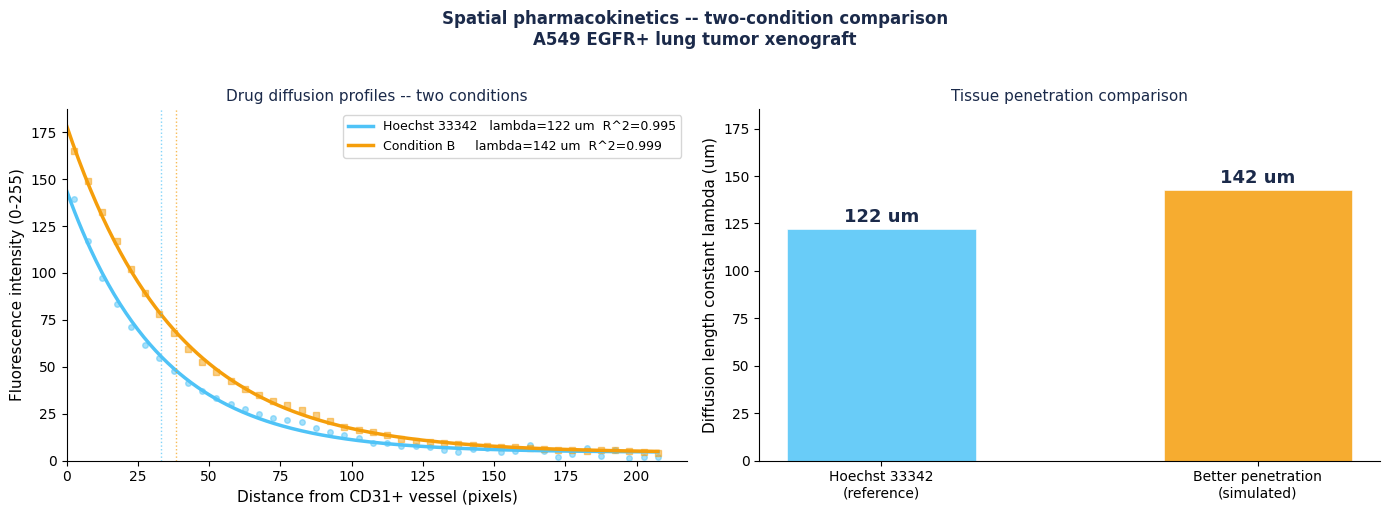

Saved to /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results/fig7_two_condition_comparison.png


In [ ]:
BLUR_SIGMA  = 15.0
hoechst_b   = gaussian_filter(hoechst_corrected, sigma=BLUR_SIGMA)
hoechst_b   = hoechst_b / hoechst_b.max()
hoechst_b_8 = (hoechst_b * 255).astype(np.float32)


def fit_profile(drug_8, dist_map, vmask, bin_size=5):
    tissue = ~vmask
    maxd   = int(np.nanmax(dist_map[tissue]))
    bins   = np.arange(0, maxd + bin_size, bin_size)
    ctrs   = bins[:-1] + bin_size / 2
    means  = []
    for i in range(len(bins)-1):
        ib = tissue & (dist_map >= bins[i]) & (dist_map < bins[i+1])
        means.append(float(drug_8[ib].mean()) if ib.sum() >= 20 else np.nan)
    means = np.array(means)
    ctrs  = ctrs[:len(means)]
    ok    = ~np.isnan(means)
    x, y  = ctrs[ok], means[ok]
    p0    = [y[0], 50.0, float(y[-5:].mean())]
    po, _ = curve_fit(exp_decay, x, y, p0=p0, maxfev=10000,
                      bounds=([0,1,0],[255,500,255]))
    yp    = exp_decay(x, *po)
    r2    = float(1 - np.sum((y-yp)**2)/np.sum((y-y.mean())**2))
    return x, y, po, r2


hoechst_a_8 = (hoechst_corrected * 255).astype(np.float32)
xa, ya, pa, r2a = fit_profile(hoechst_a_8, dist_map, vessel_mask)
xb, yb, pb, r2b = fit_profile(hoechst_b_8,  dist_map, vessel_mask)

lam_a_px, lam_b_px = pa[1], pb[1]
lam_a_um, lam_b_um = lam_a_px * PIXEL_SIZE_UM, lam_b_px * PIXEL_SIZE_UM

print('Two-condition comparison:')
print(f'  Condition A (Hoechst 33342)          : lambda = {lam_a_px:.1f} px ({lam_a_um:.0f} um)  R^2={r2a:.3f}')
print(f'  Condition B (better penetration sim) : lambda = {lam_b_px:.1f} px ({lam_b_um:.0f} um)  R^2={r2b:.3f}')
print(f'  Ratio B/A                            : {lam_b_um/lam_a_um:.2f}x')

xs = np.linspace(0, max(xa.max(), xb.max()), 300)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(xa, ya, 'o', color='#4FC3F7', markersize=4, alpha=0.5)
ax.plot(xb, yb, 's', color=AMBER,    markersize=4, alpha=0.5)
ax.plot(xs, exp_decay(xs, *pa), '-', color='#4FC3F7', linewidth=2.5,
        label=f'Hoechst 33342   lambda={lam_a_um:.0f} um  R^2={r2a:.3f}')
ax.plot(xs, exp_decay(xs, *pb), '-', color=AMBER,    linewidth=2.5,
        label=f'Condition B     lambda={lam_b_um:.0f} um  R^2={r2b:.3f}')
ax.axvline(lam_a_px, color='#4FC3F7', linewidth=1, linestyle=':', alpha=0.7)
ax.axvline(lam_b_px, color=AMBER,    linewidth=1, linestyle=':', alpha=0.7)
ax.set_xlabel('Distance from CD31+ vessel (pixels)', fontsize=11)
ax.set_ylabel('Fluorescence intensity (0-255)',       fontsize=11)
ax.set_title('Drug diffusion profiles -- two conditions', fontsize=11, color=NAVY)
ax.legend(fontsize=9)
ax.set_xlim(0)
ax.set_ylim(0)

ax2 = axes[1]
bars = ax2.bar(['Hoechst 33342\n(reference)', 'Better penetration\n(simulated)'],
               [lam_a_um, lam_b_um],
               color=['#4FC3F7', AMBER], alpha=0.85, width=0.5,
               edgecolor='white', linewidth=0.5)
for bar, val in zip(bars, [lam_a_um, lam_b_um]):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 1.5,
             f'{val:.0f} um', ha='center', va='bottom',
             fontsize=13, fontweight='bold', color=NAVY)
ax2.set_ylabel('Diffusion length constant lambda (um)', fontsize=11)
ax2.set_title('Tissue penetration comparison', fontsize=11, color=NAVY)
ax2.set_ylim(0, max(lam_a_um, lam_b_um) * 1.3)

plt.suptitle('Spatial pharmacokinetics -- two-condition comparison\n'
             'A549 EGFR+ lung tumor xenograft',
             fontsize=12, fontweight='bold', color=NAVY, y=1.02)
plt.tight_layout()
fig_path = RESULTS_DIR / 'fig7_two_condition_comparison.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {fig_path}')

---
## Cell 10: Summary figure and save results

The six-panel summary shows the complete pipeline. Panel 6 shows the predicted drug concentration map -- the exponential model applied to every tissue pixel based on its distance from the nearest vessel. This makes the spatial PK result immediately visual and interpretable.

All numerical results including the full biological context (tumor model, fluorophores, injection protocol, AF correction parameters) are saved to a CSV.

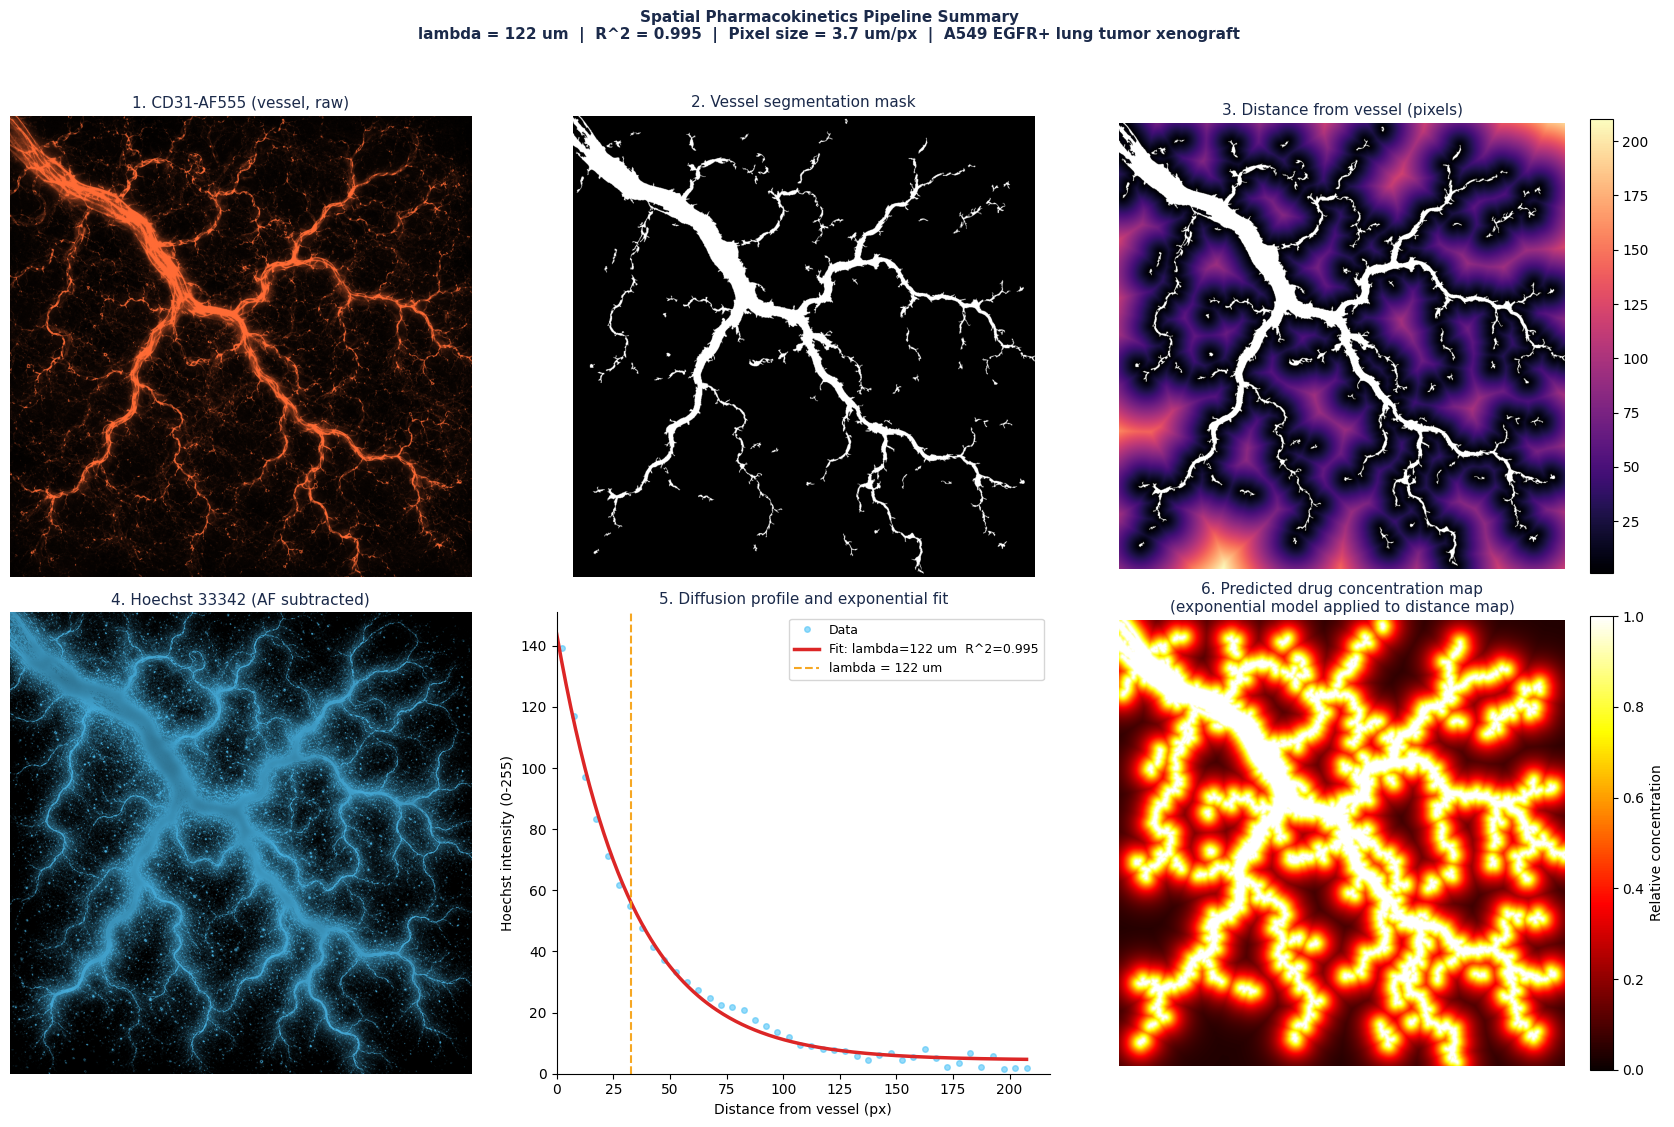

Summary figure saved to /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results/fig8_pipeline_summary.png
Results CSV saved to /content/drive/MyDrive/ColabNotebooks/AI_for_drug_discovery/Video15_spatial_pk/results/video15_spatial_pk_results.csv

All outputs saved. Video 15 pipeline complete.

Final result:
  Hoechst 33342 diffusion length lambda = 33.0 px = 122 um
  Drug concentration drops to 37% of peak at 122 um from a blood vessel.
  Drug concentration drops to 14% of peak at 244 um from a blood vessel.


In [ ]:
# Predicted drug concentration map
fitted_conc = np.zeros_like(dist_map, dtype=np.float32)
fitted_conc[~vessel_mask] = exp_decay(dist_map[~vessel_mask], *popt)
fitted_conc[vessel_mask]  = float(popt[0])
if fitted_conc.max() > 0:
    fitted_conc /= fitted_conc.max()

fig, axes = plt.subplots(2, 3, figsize=(17, 11))

axes[0,0].imshow(ch_vessel, cmap=CMAP_CD31, vmin=0, vmax=1)
axes[0,0].set_title('1. CD31-AF555 (vessel, raw)', fontsize=11, color=NAVY)
axes[0,0].axis('off')

axes[0,1].imshow(vessel_mask, cmap='gray')
axes[0,1].set_title('2. Vessel segmentation mask', fontsize=11, color=NAVY)
axes[0,1].axis('off')

im3 = axes[0,2].imshow(dist_disp, cmap='magma')
axes[0,2].set_title('3. Distance from vessel (pixels)', fontsize=11, color=NAVY)
axes[0,2].axis('off')
plt.colorbar(im3, ax=axes[0,2], fraction=0.046)

axes[1,0].imshow(hoechst_corrected, cmap=CMAP_HOECHST, vmin=0, vmax=1)
axes[1,0].set_title('4. Hoechst 33342 (AF subtracted)', fontsize=11, color=NAVY)
axes[1,0].axis('off')

ax5 = axes[1,1]
ax5.plot(x_v, y_v, 'o', color='#4FC3F7', markersize=4, alpha=0.6, label='Data')
ax5.plot(np.linspace(0, x_v.max(), 300),
         exp_decay(np.linspace(0, x_v.max(), 300), *popt),
         '-', color=RED, linewidth=2.5,
         label=f'Fit: lambda={lam_um:.0f} um  R^2={r_squared:.3f}')
ax5.axvline(lam_fit, color=AMBER, linewidth=1.5, linestyle='--', alpha=0.9,
            label=f'lambda = {lam_um:.0f} um')
ax5.set_xlabel('Distance from vessel (px)', fontsize=10)
ax5.set_ylabel('Hoechst intensity (0-255)',  fontsize=10)
ax5.set_title('5. Diffusion profile and exponential fit', fontsize=11, color=NAVY)
ax5.legend(fontsize=9)
ax5.set_xlim(0)
ax5.set_ylim(0)
ax5.spines['top'].set_visible(False)
ax5.spines['right'].set_visible(False)

im6 = axes[1,2].imshow(fitted_conc, cmap='hot', vmin=0, vmax=1)
axes[1,2].set_title('6. Predicted drug concentration map\n'
                    '(exponential model applied to distance map)', fontsize=11, color=NAVY)
axes[1,2].axis('off')
plt.colorbar(im6, ax=axes[1,2], fraction=0.046, label='Relative concentration')

plt.suptitle(
    f'Spatial Pharmacokinetics Pipeline Summary\n'
    f'lambda = {lam_um:.0f} um  |  R^2 = {r_squared:.3f}  |  '
    f'Pixel size = {PIXEL_SIZE_UM} um/px  |  A549 EGFR+ lung tumor xenograft',
    fontsize=11, fontweight='bold', color=NAVY, y=1.02
)
plt.tight_layout()
fig_path = RESULTS_DIR / 'fig8_pipeline_summary.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Summary figure saved to {fig_path}')

csv_path = RESULTS_DIR / 'video15_spatial_pk_results.csv'
with open(csv_path, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['parameter', 'value', 'unit', 'notes'])
    w.writerow(['I0',              f'{popt[0]:.3f}',       '0-255',    'Hoechst intensity at vessel wall'])
    w.writerow(['lambda_pixels',   f'{lam_fit:.3f}',       'pixels',   'Diffusion length constant'])
    w.writerow(['lambda_microns',  f'{lam_um:.2f}',        'microns',  f'At {PIXEL_SIZE_UM} um/pixel'])
    w.writerow(['C_bg',            f'{popt[2]:.3f}',       '0-255',    'Residual background after AF subtraction'])
    w.writerow(['R_squared',       f'{r_squared:.4f}',     '',         'Goodness of exponential fit'])
    w.writerow(['af_scale_factor', f'{af_scale:.4f}',      '',         'Scale factor used for AF subtraction'])
    w.writerow(['pixel_size',      f'{PIXEL_SIZE_UM}',     'um/pixel', '4x objective'])
    w.writerow(['otsu_threshold',  f'{otsu_thresh}',       '0-255',    'CD31 vessel segmentation threshold'])
    w.writerow(['vessel_fraction', f'{vessel_mask.mean()*100:.2f}', '%', 'Fraction of image occupied by vessels'])
    w.writerow(['image_size',      f'{H}x{W}',             'pixels',   'Input image dimensions'])
    w.writerow(['drug_marker',     'Hoechst 33342',        '',         'IV 10 mg/kg, 1 hour before sacrifice'])
    w.writerow(['vessel_marker',   'CD31-AlexaFluor 555',  '',         'Ex-vivo, 10 um cryosection'])
    w.writerow(['tumor_model',     'A549 EGFR+ lung xenograft', '',    'Nude mouse subcutaneous tumor'])
    w.writerow(['af_source',       'Collagen/elastin (vessel walls), NAD(P)H (cells)', '', 'Spatially structured AF'])

print(f'Results CSV saved to {csv_path}')
print('\nAll outputs saved. Video 15 pipeline complete.')
print(f'\nFinal result:')
print(f'  Hoechst 33342 diffusion length lambda = {lam_fit:.1f} px = {lam_um:.0f} um')
print(f'  Drug concentration drops to 37% of peak at {lam_um:.0f} um from a blood vessel.')
print(f'  Drug concentration drops to 14% of peak at {2*lam_um:.0f} um from a blood vessel.')